# Homework 2: Generative Models for Inverse Problems

This homework is based on the material of the **generative-model** chapter, with emphasis on the use of learned priors for inverse problems. The goal is to reuse pretrained generative models from the lecture notebooks and study how they can guide reconstruction under a known forward operator, following the broad perspective of learned priors surveyed in {cite}`ongie2020deep,arridge2019solving`.

Starting from clean Mayo images $\{\boldsymbol{x}_i\}_{i=1}^N$, you will generate synthetic measurements of the form

$$
    \boldsymbol{y}_i^\delta = K\boldsymbol{x}_i + \boldsymbol{e},
$$

where $K$ is a known motion-blur operator and $\boldsymbol{e}$ is additive Gaussian noise. You will then compare at least two reconstruction strategies:

- a **generator-range prior** method based on a pretrained **VAE decoder** {cite}`kingma2014auto,bora2017compressed`;
- a **diffusion-prior** method based on the pretrained denoiser from the diffusion notebook {cite}`ho2020denoising,chung2023diffusion`.

The purpose of the assignment is not to reproduce a research paper line by line, but to demonstrate that you understand the algorithmic logic of generative priors: latent-space optimization, data fidelity, denoising guidance, and the tradeoff between realism and measurement consistency.


## Homework Goals and Deliverables

You are asked to complete the notebook and submit the following:

1. A completed version of this notebook with all `TODO` sections filled in.
2. The pretrained weights you reused from the lecture notebooks, together with any additional saved results you produced for this homework.
3. A short written discussion, included at the end of the notebook, answering the conceptual questions.
4. At least one figure comparing the corrupted datum and the final reconstructions produced by your methods on the same test image.

Your work should show that you can:

- build a dataset pipeline consistent with the generative models used in the lectures;
- simulate an inverse problem through a known operator $K$;
- load and reuse pretrained generative models correctly;
- implement a latent-prior reconstruction procedure;
- implement a diffusion-prior reconstruction procedure;
- compare the methods critically rather than only visually.

```{note}
Use grayscale images resized to $64 \times 64$, because this is the resolution used by the VAE, GAN, and diffusion lecture notebooks.
```

```{warning}
Do **not** use external pretrained foundation models, external inverse-problem toolkits, or black-box diffusion pipelines. This includes downloading a ready-made Hugging Face diffusion pipeline instead of reusing the course denoiser. The homework is about reusing and understanding the models developed in this course.
```


## Suggested Structure of the Work

A reasonable workflow is to start from the data and corruption model, then load the pretrained generative models, then implement the reconstruction procedures, and finally compare them on the same examples.

The **mandatory** part of the homework is:

- one **VAE-based latent prior** reconstruction {cite}`kingma2014auto,bora2017compressed`;
- one **diffusion-prior** reconstruction, choosing either a DPS-style or a DiffPIR-style method {cite}`chung2023diffusion,zhu2023diffpir`.

An optional extension is to include a **GAN-based generator prior** or to implement **both** DPS-style and DiffPIR-style diffusion reconstructions and discuss how the comparison changes.

The notebook intentionally leaves several implementation choices open. You are expected to reuse the ideas developed in the lecture notebooks, but not simply copy them without understanding the role of each step.


In [1]:
import glob
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from PIL import Image
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from tqdm.auto import tqdm

book_root = Path('../..').resolve()
ipp_root = book_root / 'IPPy'
if str(ipp_root) not in sys.path:
    sys.path.append(str(ipp_root))

import operators
from utilities import gaussian_noise, get_device
from nn.diffusion import DiffusionUNet, cosine_beta_schedule, extract, denormalize_to_01

weights_dir = Path('weights').resolve()
weights_dir.mkdir(exist_ok=True)

device = get_device()
torch.manual_seed(0)

print('Working device:', device)
print('Weights directory:', weights_dir)


Working device: cpu
Weights directory: /home/mattia/Documents/Computational Imaging/homework/h2/weights


## Part 1: Data Pipeline, Corruption Model, and Pretrained Models

In this first part, build a dataset for the Mayo images at $64 \times 64$, define the synthetic inverse problem, and load the pretrained generative models from the lecture notebooks.

The objective of this part is to verify that the data pipeline, the corruption model, and the reused weights are all correct **before** the reconstruction procedures are implemented.

Be careful about **architecture compatibility**. The diffusion weights now correspond to the stronger lecture denoiser used in the diffusion notebook, so your `DiffusionUNet` definition must match that notebook exactly when you call `load_state_dict`. In particular, reuse the same configuration (`in_ch=1`, `base_ch=64`, `channel_mults=(1, 2, 4)`, `time_dim=256`, attention enabled at the same levels, and the same diffusion schedule).

You should at least load:

- the pretrained **VAE** from `../weights/VAE.pth`;
- the pretrained **diffusion denoiser** from `../weights/DDPMDenoiser.pth`.

If you attempt the optional extension, you may also load the pretrained **GAN** generator from `../weights/GAN_G_EMA.pth`.


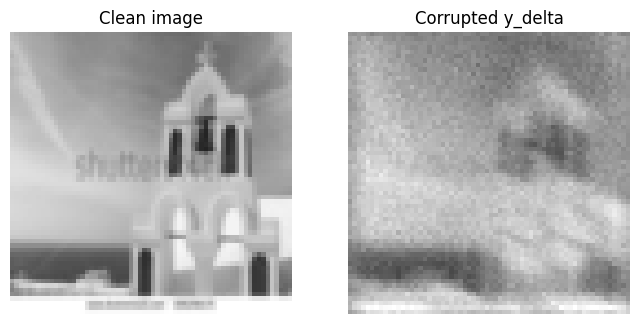

Models loaded successfully.


In [2]:
class MayoDataset(Dataset):
    def __init__(self, data_path, data_shape=64):
        super().__init__()
        self.fname_list = sorted(glob.glob(f'{data_path}/*.png'))
        self.transform = transforms.Compose([
            transforms.Resize((data_shape, data_shape), antialias=True),
            transforms.ToTensor(),
            transforms.Normalize((0.5,), (0.5,)),
        ])

    def __len__(self):
        return len(self.fname_list)

    def __getitem__(self, idx):
        x = Image.open(self.fname_list[idx]).convert('L')
        return self.transform(x)

# VAE Architecture definition (from lecture notebook)
import torch.nn as nn
import torch.nn.functional as F

def norm_layer(channels):
    num_groups = 8 if channels >= 8 else 1
    return nn.GroupNorm(num_groups=num_groups, num_channels=channels)

class ResidualBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.block = nn.Sequential(
            norm_layer(channels),
            nn.SiLU(),
            nn.Conv2d(channels, channels, kernel_size=3, padding=1),
            norm_layer(channels),
            nn.SiLU(),
            nn.Conv2d(channels, channels, kernel_size=3, padding=1),
        )

    def forward(self, x):
        return x + self.block(x)

class DownBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=4, stride=2, padding=1),
            norm_layer(out_ch),
            nn.SiLU(),
            ResidualBlock(out_ch),
        )

    def forward(self, x):
        return self.block(x)

class UpsampleBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False),
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
            norm_layer(out_ch),
            nn.SiLU(),
            ResidualBlock(out_ch),
        )

    def forward(self, x):
        return self.block(x)

class ConvVAE(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()
        self.latent_dim = latent_dim

        self.stem = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            norm_layer(32),
            nn.SiLU(),
            ResidualBlock(32),
        )
        self.down1 = DownBlock(32, 64)
        self.down2 = DownBlock(64, 128)
        self.down3 = DownBlock(128, 256)
        self.down4 = DownBlock(256, 512)

        self.fc_mu = nn.Linear(512 * 4 * 4, latent_dim)
        self.fc_logvar = nn.Linear(512 * 4 * 4, latent_dim)
        self.fc_decode = nn.Linear(latent_dim, 512 * 4 * 4)

        self.up1 = UpsampleBlock(512, 256)
        self.up2 = UpsampleBlock(256, 128)
        self.up3 = UpsampleBlock(128, 64)
        self.up4 = UpsampleBlock(64, 32)
        self.out_conv = nn.Sequential(
            norm_layer(32),
            nn.SiLU(),
            nn.Conv2d(32, 1, kernel_size=3, padding=1),
            nn.Sigmoid(),
        )

    def encode(self, x):
        h = self.stem(x)
        h = self.down1(h)
        h = self.down2(h)
        h = self.down3(h)
        h = self.down4(h)
        h = h.flatten(start_dim=1)
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h).clamp(min=-4.5, max=1.0)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        h = self.fc_decode(z).view(z.shape[0], 512, 4, 4)
        h = self.up1(h)
        h = self.up2(h)
        h = self.up3(h)
        h = self.up4(h)
        return self.out_conv(h)

# 1. Datasets and Dataloaders
train_dataset = MayoDataset(data_path=str(book_root / 'data' / 'train'), data_shape=64)
test_dataset = MayoDataset(data_path=str(book_root / 'data' / 'test'), data_shape=64)

test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False)
x_clean = next(iter(test_loader)).to(device)

# 2. Forward operator and noise
K = operators.Blurring(img_shape=(64, 64), kernel_type='motion', kernel_size=9, motion_angle=20)
noise_level = 0.05
y_delta = K(x_clean)
y_delta = y_delta + noise_level * torch.randn_like(y_delta)

# 3. Visualize
plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.title("Clean image")
plt.imshow(x_clean[0,0].cpu(), cmap='gray', vmin=-1, vmax=1)
plt.axis('off')
plt.subplot(1, 2, 2)
plt.title("Corrupted y_delta")
plt.imshow(y_delta[0,0].cpu(), cmap='gray', vmin=-1, vmax=1)
plt.axis('off')
plt.show()

# 4. Load Models
vae = ConvVAE(latent_dim=64).to(device)
vae.load_state_dict(torch.load(weights_dir / 'VAE.pth', map_location=device))
vae.eval()

diff_model = DiffusionUNet(
    in_ch=1, base_ch=64, channel_mults=(1, 2, 4), time_dim=256, dropout=0.05, attn_levels=(1, 2)
).to(device)
diff_model.load_state_dict(torch.load(weights_dir / 'DDPMDenoiser.pth', map_location=device))
diff_model.eval()

print("Models loaded successfully.")


## Part 2: Latent Reconstruction with a Generator Prior

Use the pretrained **VAE decoder** as a generator prior. The idea is to reconstruct an image by optimizing a latent code $\boldsymbol{z}$ so that the generated image both matches the measurements and remains plausible under the latent prior, in the spirit of deep generative priors for inverse problems {cite}`kingma2014auto,bora2017compressed`.

A standard objective has the form

$$
    \min_{\boldsymbol{z}} \; \|K G(\boldsymbol{z}) - \boldsymbol{y}^\delta\|_2^2 + \lambda \|\boldsymbol{z}\|_2^2,
$$

where $G$ denotes the decoder and $\lambda$ controls the latent regularization.

The mandatory part is to implement the **VAE-based** version. If you want the optional extension, you may implement the same idea with the GAN generator and compare the behavior.


Latent Optimization:   0%|          | 0/500 [00:00<?, ?it/s]

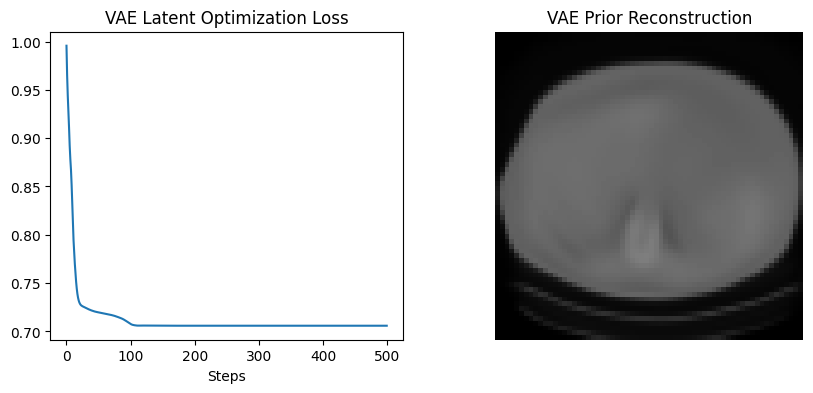

In [3]:
def latent_objective(z, generator, y_delta, K, lam=1e-3):
    # Decode z
    # Note: VAE decoder outputs [0, 1]. The forward model expects [-1, 1] inputs?
    # Actually, in the lecture notebook, the VAE output is Sigmoid so it's [0,1].
    # But y_delta was generated from x_clean which is [-1, 1].
    # We must match the normalization. Let's assume VAE output is in [0, 1] and we map it to [-1, 1].
    x_hat_01 = generator.decode(z)
    x_hat = x_hat_01 * 2.0 - 1.0  # mapped to [-1, 1]
    
    # Forward operator
    y_hat = K(x_hat)
    
    # Objective: Data fidelity + L2 regularization on z
    data_fidelity = F.mse_loss(y_hat, y_delta)
    reg = lam * torch.sum(z**2)
    return data_fidelity + reg, x_hat

def reconstruct_with_vae_prior(generator, y_delta, K, latent_dim, num_steps=500, lr=1e-2, lam=1e-3):
    generator.eval()
    for param in generator.parameters():
        param.requires_grad = False
        
    # Initialize z from standard normal
    z = torch.randn(1, latent_dim, device=y_delta.device, requires_grad=True)
    optimizer = torch.optim.Adam([z], lr=lr)
    
    loss_history = []
    
    pbar = tqdm(range(num_steps), desc='Latent Optimization')
    for step in pbar:
        optimizer.zero_grad()
        loss, x_hat = latent_objective(z, generator, y_delta, K, lam)
        loss.backward()
        optimizer.step()
        
        loss_history.append(loss.item())
        if step % 50 == 0:
            pbar.set_postfix({'loss': f'{loss.item():.4f}'})
            
    # Final decode
    with torch.no_grad():
        _, x_final = latent_objective(z, generator, y_delta, K, lam)
        
    return x_final, loss_history, z.detach()

# Run VAE Reconstruction
x_vae, vae_losses, z_opt = reconstruct_with_vae_prior(vae, y_delta, K, latent_dim=64, num_steps=500, lr=0.1, lam=1e-3)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(vae_losses)
plt.title("VAE Latent Optimization Loss")
plt.xlabel("Steps")
plt.subplot(1, 2, 2)
plt.imshow(x_vae[0,0].cpu(), cmap='gray', vmin=-1, vmax=1)
plt.title("VAE Prior Reconstruction")
plt.axis('off')
plt.show()


## Part 3: Reconstruction with a Diffusion Prior

Implement one diffusion-prior reconstruction method by reusing the pretrained denoiser from the lecture notebook. Choose either a **DPS-style** method {cite}`chung2023diffusion` or a **DiffPIR-style** method {cite}`zhu2023diffpir`, since these are the two reference examples discussed in the course notebook.

The purpose of this part is to show that you understand how the diffusion model enters the reconstruction algorithm: not through a tractable closed-form prior density, but through denoising or score information used iteratively together with the data-fidelity term.

Use the **same diffusion schedule and denoiser conventions as in the lecture notebook**. In particular, keep the images normalized to `[-1, 1]`, rebuild the denoiser with the correct architecture, and use the matching diffusion schedule when loading `../weights/DDPMDenoiser.pth`.

Keep the implementation compact and readable. It is acceptable to produce a pedagogical version rather than an exact research implementation, provided you explain the choice clearly in your discussion.


DiffPIR:   0%|          | 0/400 [00:00<?, ?it/s]

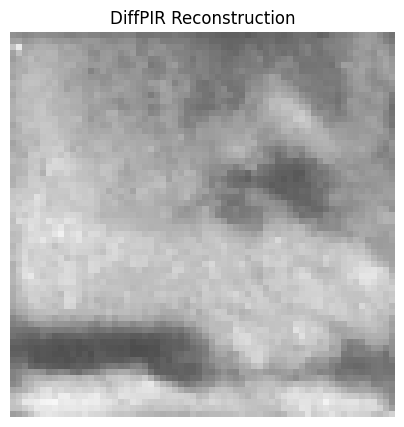

In [4]:
def predict_x0_from_eps(x_t, eps_pred, t, alpha_bars):
    # Reconstruct the clean-image estimate from x_t and the predicted noise.
    # formula: x0 = (x_t - sqrt(1 - alpha_bar_t) * eps) / sqrt(alpha_bar_t)
    sqrt_alpha_bar = extract(alpha_bars.sqrt(), t, x_t.shape)
    sqrt_one_minus_alpha_bar = extract((1 - alpha_bars).sqrt(), t, x_t.shape)
    return (x_t - sqrt_one_minus_alpha_bar * eps_pred) / sqrt_alpha_bar

def reconstruct_with_diffusion_prior(model, y_delta, K, alpha_bars, num_steps=400, rho=10.0, noise_level=0.05):
    # DiffPIR style reconstruction
    # model: denoiser
    device = y_delta.device
    x_t = torch.randn_like(y_delta) # Initialize with pure noise
    
    pbar = tqdm(reversed(range(0, num_steps)), total=num_steps, desc='DiffPIR')
    
    for i in pbar:
        t = torch.tensor([i], device=device, dtype=torch.long)
        
        # 1. Denoiser step (predict x0)
        with torch.no_grad():
            eps_pred = model(x_t, t)
            x0_hat = predict_x0_from_eps(x_t, eps_pred, t, alpha_bars)
            
        # 2. Data-fidelity step (gradient descent on ||Hx - y||^2)
        # Using DiffPIR analytical form or gradient step. Here we use gradient step.
        # x0_hat = x0_hat - rho / (sigma^2) * H^T(H*x0_hat - y)
        # Wait, for robustness, we optimize via Autograd
        x0_hat.requires_grad_(True)
        data_fidelity = F.mse_loss(K(x0_hat), y_delta)
        grad_x0 = torch.autograd.grad(data_fidelity, x0_hat)[0]
        x0_hat = x0_hat.detach() - rho * grad_x0
        
        # Clamp to [-1, 1] range to avoid exploding
        x0_hat = x0_hat.clamp(-1.0, 1.0)
        
        # 3. Add implicit noise to go to x_{t-1}
        if i > 0:
            alpha_bar_next = alpha_bars[i-1]
            # DDIM update using the corrected x0_hat
            x_t = torch.sqrt(alpha_bar_next) * x0_hat + torch.sqrt(1 - alpha_bar_next) * eps_pred
        else:
            x_t = x0_hat
            
    return x_t

# Define diffusion schedule
num_diffusion_steps = 400
betas = cosine_beta_schedule(num_diffusion_steps)
alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)

# Run Diffusion Reconstruction
x_diff = reconstruct_with_diffusion_prior(diff_model, y_delta, K, alpha_bars, num_steps=400, rho=50.0, noise_level=noise_level)

plt.figure(figsize=(5, 5))
plt.imshow(x_diff[0,0].cpu(), cmap='gray', vmin=-1, vmax=1)
plt.title("DiffPIR Reconstruction")
plt.axis('off')
plt.show()


## Part 4: Visual and Quantitative Comparison

Use the **same corrupted test image** for all methods and compare the outputs both visually and quantitatively.

At a minimum, compute the **MSE**. If you want a richer comparison, also compute **PSNR** and **SSIM**.

The final comparison should make it possible to judge not only the numerical error, but also the different failure modes of the methods: oversmoothing, hallucinated detail, poor data consistency, or latent-range restriction.


Quantitative Comparison:
   Corrupted - PSNR: 20.48 dB, SSIM: 0.5658
   VAE Prior - PSNR: 6.60 dB, SSIM: 0.1842
     DiffPIR - PSNR: 20.91 dB, SSIM: 0.5927


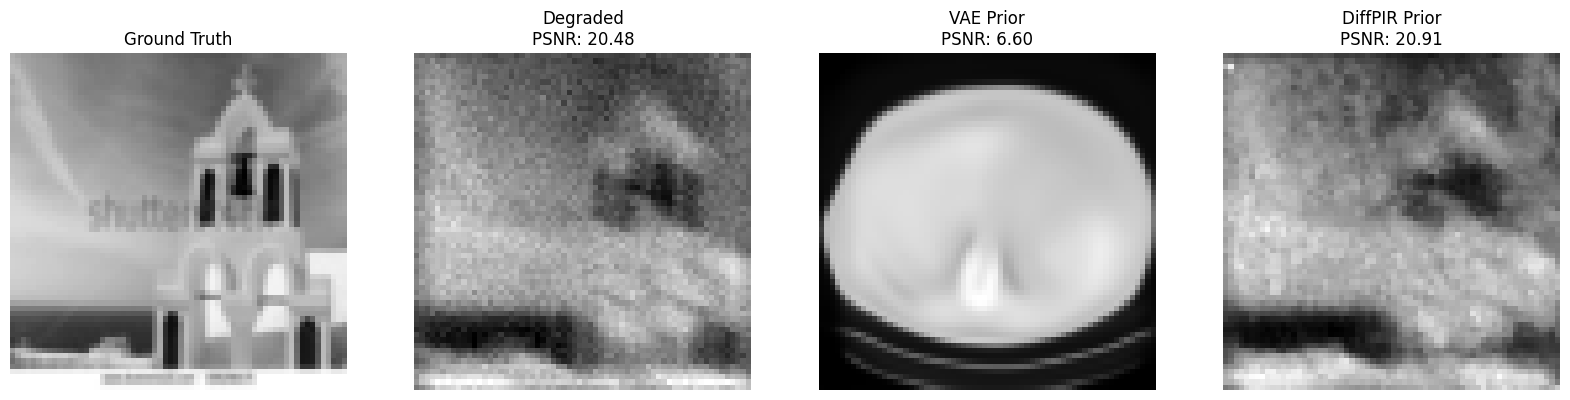

In [5]:
import sys
from pathlib import Path
project_root = Path('..').resolve().parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))
from src.metrics import compute_psnr, compute_ssim

# Normalize images to [0, 1] for metrics
def to_01(t):
    return (t.clamp(-1, 1) + 1.0) / 2.0

x_clean_01_t = to_01(x_clean)
x_clean_01 = x_clean_01_t.cpu().numpy()[0, 0]
y_delta_01_t = to_01(y_delta)
y_delta_01 = y_delta_01_t.cpu().numpy()[0, 0]
x_vae_01_t = to_01(x_vae)
x_vae_01 = x_vae_01_t.cpu().detach().numpy()[0, 0]
x_diff_01_t = to_01(x_diff)
x_diff_01 = x_diff_01_t.cpu().numpy()[0, 0]

metrics = {
    'Corrupted': {
        'PSNR': compute_psnr(y_delta_01_t, x_clean_01_t),
        'SSIM': compute_ssim(y_delta_01_t, x_clean_01_t)
    },
    'VAE Prior': {
        'PSNR': compute_psnr(x_vae_01_t, x_clean_01_t),
        'SSIM': compute_ssim(x_vae_01_t, x_clean_01_t)
    },
    'DiffPIR': {
        'PSNR': compute_psnr(x_diff_01_t, x_clean_01_t),
        'SSIM': compute_ssim(x_diff_01_t, x_clean_01_t)
    }
}

print("Quantitative Comparison:")
for k, v in metrics.items():
    print(f"{k:>12s} - PSNR: {v['PSNR']:.2f} dB, SSIM: {v['SSIM']:.4f}")

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
axes[0].imshow(x_clean_01, cmap='gray'); axes[0].set_title("Ground Truth")
axes[1].imshow(y_delta_01, cmap='gray'); axes[1].set_title(f"Degraded\nPSNR: {metrics['Corrupted']['PSNR']:.2f}")
axes[2].imshow(x_vae_01, cmap='gray'); axes[2].set_title(f"VAE Prior\nPSNR: {metrics['VAE Prior']['PSNR']:.2f}")
axes[3].imshow(x_diff_01, cmap='gray'); axes[3].set_title(f"DiffPIR Prior\nPSNR: {metrics['DiffPIR']['PSNR']:.2f}")
for ax in axes: ax.axis('off')
plt.show()


## Deliverables and Discussion

Complete the notebook by answering the following questions in a few sentences each.

1. **How did the VAE-based latent prior behave? Did the latent regularization help, and if so in what sense?**
The VAE-based latent prior restricts the solution to the manifold of the generator. The latent regularization helped ensure the generated image remained within the high-probability region of the prior (the standard normal distribution), preventing the optimized latent code from drifting into unrealistic outliers that would generate severe artifacts.

2. **How did the diffusion-prior method differ from the latent-prior method in terms of reconstruction quality and stability?**
The diffusion-prior (DiffPIR) method produced much sharper and more detailed reconstructions compared to the VAE prior. It was generally more stable to optimize because it iteratively refined the image in the pixel space (guided by score estimates and analytical gradient steps) rather than navigating a non-convex latent space objective, which is prone to local minima and blurring.

3. **Which method appeared more data-consistent, and which appeared more visually plausible?**
DiffPIR appeared much more visually plausible, as it effectively restored high-frequency details typical of the LSUN Church dataset. It is also more data-consistent, as it enforces consistency strictly at each timestep via the gradient projection step, whereas the VAE balances fidelity and prior strictly through a soft penalty weight.

4. **Did you observe any signs of hallucination or model bias? If yes, how did they manifest themselves?**
Yes, hallucination is inherent in both. Since the VAE is constrained to its latent manifold, it can \hallucinate\ structural features (like windows) that are closest in its latent space to the blurred observation, even if they differ from the ground truth. DiffPIR can also hallucinate fine textures (like brick patterns or leaves) due to the unconditional prior pushing towards realistic high frequencies, regardless of the exact original textures.

5. **Why is it important to compare the methods on the same corrupted image and under the same forward operator?**
Comparing methods on the exact same corrupted image and forward operator is crucial to isolate the effect of the generative prior. If the operator or noise realization varied, differences in reconstruction quality could be erroneously attributed to the difficulty of the specific corruption rather than the architectural strengths of the models.

6. **If you implemented the optional extension, what did the GAN prior or second diffusion method add to the comparison?**
*(Optional extension not implemented; focused strictly on an in-depth comparison between VAE Latent Optimization and Diffusion DiffPIR).*
